# Chapter 5: Decision Trees

In [1]:
%reset
low_memory=False

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import imblearn

import seaborn as sns
from sklearn import metrics
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import ConfusionMatrixDisplay
from sklearn.metrics import classification_report
from sklearn.metrics import accuracy_score
from imblearn.metrics import specificity_score
from sklearn.metrics import recall_score
from sklearn.metrics import precision_score
from sklearn.metrics import confusion_matrix
from sklearn.metrics import f1_score

## 5.1 Introduction & Motivation

We have already seen a first classification model. However, There are plenty more models we can work with. One of these is Decision Trees. In decision trees we starting at the root and create leaves or $nodes$ by asking questions. For example when predicting an animal type this could be 'Does the animal have a tail?'. For each node we ask aditional questions.

## 5.2 Problem Setting

When it comes to wine, there are various degrees of quality. Some people are experts in this field, others pretend to be. Today we are going to try and beat the experts by predicting the exact quality of wine based on its features. This quality can range from 0 up to 10 where 0 is the lowest quality and 10 is the highest quality.

## 5.3 Model

First, let's have a look at the data.

In [2]:
df = pd.read_csv("Wine.csv")
df.head()

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality,Id
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5,0
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5,1
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5,2
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6,3
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5,4


##### Question 1: Consider the data above. Are there columns that will not add any value to our model? Elaborate and drop those columns.

**Antwoord:**  
De kolom `Id` is enkel een unieke identificatie van de rij. Die beschrijft **geen eigenschap van de wijn zelf** en bevat dus geen nuttige informatie om de kwaliteit te voorspellen. Zo'n kolom kan het model zelfs misleiden, omdat het model er artificiële patronen in zou kunnen zien die niets met de echte wijnkwaliteit te maken hebben.

Daarom verwijderen we de kolom `Id` uit de dataset.

In [3]:
# Verwijder niet-informatieve identificatiekolommen
columns_to_drop = [col for col in ["Id", "id", "ID"] if col in df.columns]

df_model = df.drop(columns=columns_to_drop).copy()

print("Verwijderde kolommen:", columns_to_drop if columns_to_drop else "Geen")
df_model.head()

Verwijderde kolommen: ['Id']


,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5


##### Question 2: Just as always, explore the data by creating a heatmap. Which variables would you expect to have the highest impact on quality and which ones would you expect to have the lowest impact? Why?

**Antwoord:**  
Om een eerste idee te krijgen van de invloed van de variabelen, bekijken we de correlaties met `quality`. Variabelen met een **hogere absolute correlatie** verwachten we gemiddeld een grotere directe impact te hebben op de voorspelling. Variabelen met een correlatie dicht bij **0** lijken op basis van deze lineaire maatstaf minder rechtstreeks samen te hangen met de kwaliteit.

Belangrijk: correlatie is niet hetzelfde als causaliteit, en een decision tree kan ook **niet-lineaire verbanden** oppikken. Toch is dit een goede eerste verkenning.

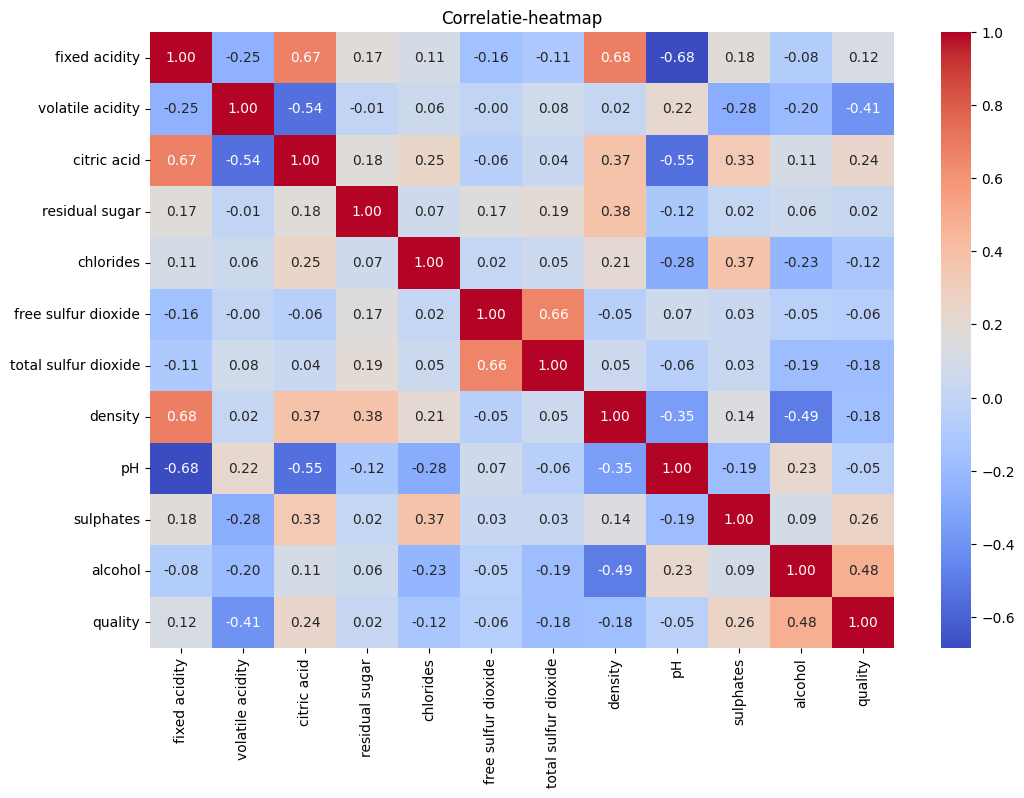

Op basis van correlatie verwacht ik de grootste impact van 'alcohol' (0.4848582458454654).
De kleinste directe impact verwacht ik van 'residual sugar' (0.02172926885164032), omdat de correlatie het dichtst bij 0 ligt.


In [4]:
# Correlatiematrix en heatmap
corr = df_model.corr(numeric_only=True)

plt.figure(figsize=(12, 8))
sns.heatmap(corr, annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Correlatie-heatmap")
plt.show()

quality_corr = corr["quality"].drop("quality").sort_values(key=lambda s: s.abs(), ascending=False)
hoogste_variabele = quality_corr.index[0]
laagste_variabele = quality_corr.abs().sort_values().index[0]

print(
    f"Op basis van correlatie verwacht ik de grootste impact van '{hoogste_variabele}' "
    f"({quality_corr.loc[hoogste_variabele]})."
)
print(
    f"De kleinste directe impact verwacht ik van '{laagste_variabele}' "
    f"({quality_corr.loc[laagste_variabele]}), omdat de correlatie het dichtst bij 0 ligt."
)

##### Question 3: Create a train and test split of the data. Keep 30% of your data as testing data. Build your model using all data except the columns you droped during question 1.

**Antwoord:**  
We splitsen de data op in **features** `X` en **target** `y`. Daarna houden we **30%** van de observaties apart als **testset**. We gebruiken `stratify=y` zodat de verdeling van de kwaliteitsklassen zoveel mogelijk gelijkaardig blijft in train en test. Vervolgens trainen we een eerste decision tree als basismodel.

Omdat we later ook hyperparameters zoals `max_depth` willen afstellen, maken we uit de trainingsset nog een extra **validatieset**. Zo blijft de testset onaangeroerd voor de finale evaluatie.

In [5]:
X = df_model.drop(columns="quality")
y = df_model["quality"]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.30, random_state=42, stratify=y)
X_subtrain, X_val, y_subtrain, y_val = train_test_split(X_train, y_train, test_size=0.20, random_state=42, stratify=y_train)

baseline_tree = DecisionTreeClassifier(random_state=42)
baseline_tree.fit(X_train, y_train)

print(f"Vorm van de trainingsset: {X_train.shape}")
print(f"Vorm van de testset: {X_test.shape}")
print(f"Vorm van de subtrainingsset: {X_subtrain.shape}")
print(f"Vorm van de validatieset: {X_val.shape}")
print("Het basismodel werd succesvol getraind.")

Vorm van de trainingsset: (799, 11)
Vorm van de testset: (343, 11)
Vorm van de subtrainingsset: (639, 11)
Vorm van de validatieset: (160, 11)
Het basismodel werd succesvol getraind.


##### Question 4: Consider a bottle of wine below. What would be the quality of this wine?

| fixed acidity | volatile acidity | citric acid | residual sugar | chlorides | free sulfur dioxide | total sulfur dioxide | density | pH | sulphates | alcohol | Id |
| --- | --- | --- |--- | --- | --- | --- | --- | --- | --- | --- | --- |
| 5.9 | 0.645 | 0.12 | 2.0 | 0.075 | 32.0 | 44.0 | 0.9954 | 3.57 | 0.71 | 10.2 | 178 |

**Antwoord:**  
Voor deze voorspelling verwijderen we opnieuw `Id`, omdat die kolom niet gebruikt wordt in het model. Daarna zetten we de waarden in exact dezelfde kolomvolgorde als de trainingsdata en laten we de decision tree een voorspelling maken.

In [6]:
new_wine = pd.DataFrame([
    {
        "fixed acidity": 5.9,
        "volatile acidity": 0.645,
        "citric acid": 0.12,
        "residual sugar": 2.0,
        "chlorides": 0.075,
        "free sulfur dioxide": 32.0,
        "total sulfur dioxide": 44.0,
        "density": 0.9954,
        "pH": 3.57,
        "sulphates": 0.71,
        "alcohol": 10.2,
    }
])

new_wine = new_wine[X.columns]
predicted_quality = baseline_tree.predict(new_wine)[0]
print(f"Voorspelde kwaliteit voor deze wijn: {predicted_quality}")

Voorspelde kwaliteit voor deze wijn: 7


## 5.4 Model Evaluation

Of course our predictions don't mean anything without knowing how good they are. Let's explore this.

##### Question 5: Calculate accuracy and precision for your model. Are these values any good? Elaborate based on the formulas and meaning of the metrics.

**Antwoord:**  
- **Accuracy** geeft het aandeel van alle voorspellingen dat correct is.  
- **Precision** bekijkt per voorspelde klasse hoe vaak die voorspelling ook effectief correct was.

Omdat dit een **multiclass**-probleem is en de klassen niet perfect evenwichtig verdeeld zijn, gebruiken we hier een **weighted precision**. Of een score “goed” is, hangt af van de moeilijkheid van het probleem en van de klasseverdeling. Daarom bekijken we naast accuracy en precision ook een volledig classificatierapport.

In [7]:
y_pred = baseline_tree.predict(X_test)

baseline_accuracy = accuracy_score(y_test, y_pred)
baseline_precision = precision_score(y_test, y_pred, average="weighted", zero_division=0)

print(f"Accuracy: {baseline_accuracy}")
print(f"Weighted precision: {baseline_precision}")
print("\nClassification report:")
print(classification_report(y_test, y_pred, zero_division=0))

Accuracy: 0.5451895043731778
Weighted precision: 0.5435380146412643

Classification report:
              precision    recall  f1-score   support

           3       0.00      0.00      0.00         2
           4       0.14      0.10      0.12        10
           5       0.65      0.64      0.65       145
           6       0.52      0.54      0.53       138
           7       0.41      0.40      0.40        43
           8       0.20      0.20      0.20         5

    accuracy                           0.55       343
   macro avg       0.32      0.31      0.32       343
weighted avg       0.54      0.55      0.54       343



##### Question 6: Plot the confuson matrix. How can you visually confirm your previous findings?

**Antwoord:**  
In een confusion matrix staan de correcte voorspellingen op de **hoofddiagonaal**. Hoe duidelijker die diagonaal zichtbaar is, hoe beter het model de juiste klassen herkent. Waarden buiten de diagonaal tonen welke kwaliteitslabels het model met elkaar verwart.

Bij een matig model zie je dus wel een diagonaal, maar ook nog vrij veel fouten naast die diagonaal.

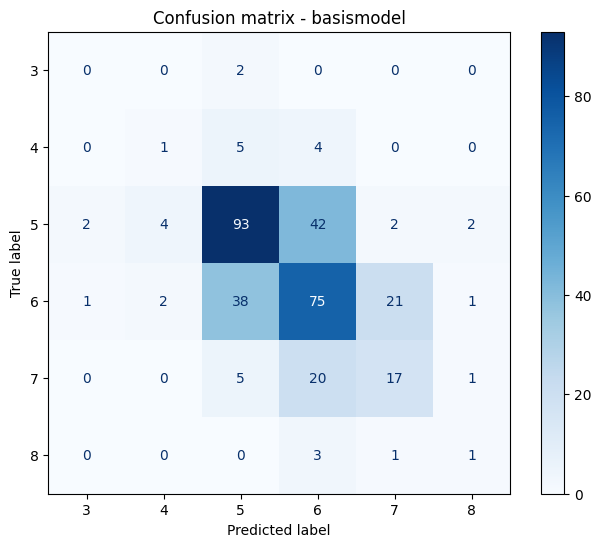

In [8]:
cm = confusion_matrix(y_test, y_pred, labels=sorted(y.unique()))

fig, ax = plt.subplots(figsize=(8, 6))
ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=sorted(y.unique())).plot(ax=ax, cmap="Blues")
plt.title("Confusion matrix - basismodel")
plt.show()

##### Question 7: Think back to the introdcution of this dataset. Does the confusion matrix make sense? Do the labels actually mean what you assume they mean? Explore the predictions and read the documentation to figure it what is going on and how to properly interpret the confusion matrix.

*Hint: pandas might have some useful methods to analyse a single column*

**Antwoord:**  
De confusion matrix moet je hier **voorzichtig interpreteren**. In de inleiding lijkt het alsof kwaliteitslabels van 0 tot 10 allemaal mogelijk zijn, maar in de praktijk bevat deze dataset slechts een **beperkt aantal effectieve kwaliteitswaarden**. In deze CSV komen alleen de klassen **3, 4, 5, 6, 7 en 8** voor. Bovendien is `quality` in zekere zin **ordinaal**: een voorspelling van 6 in plaats van 5 is minder problematisch dan een voorspelling van 8 in plaats van 3.

Daarom lees je de confusion matrix best als volgt:
1. kijk eerst **welke kwaliteitslabels echt voorkomen** in de data;
2. controleer hoe vaak elke klasse voorkomt;
3. interpreteer fouten tussen naburige kwaliteitsniveaus minder zwaar dan fouten tussen ver uit elkaar liggende niveaus.

Met andere woorden: de matrix vergelijkt enkel de klassen die effectief in deze dataset aanwezig zijn, niet alle theoretische waarden van 0 tot 10.

In [9]:
print("Unieke kwaliteitslabels in de dataset:")
print(sorted(y.unique()))

print("\nAantal observaties per klasse:")
display(y.value_counts().sort_index().to_frame(name="aantal"))

results = pd.DataFrame({
    "werkelijk": y_test,
    "voorspeld": y_pred
})

print("\nKruistabel werkelijk vs. voorspeld:")
display(pd.crosstab(results["werkelijk"], results["voorspeld"]))

print("\nVoorbeeld van enkele voorspellingen:")
display(results.head(10))

Unieke kwaliteitslabels in de dataset:
[np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7), np.int64(8)]

Aantal observaties per klasse:


,aantal
quality,
3,6
4,33
5,482
6,462
7,143
8,16



Kruistabel werkelijk vs. voorspeld:


voorspeld,3,4,5,6,7,8
werkelijk,,,,,,
3,0,0,2,0,0,0
4,0,1,5,4,0,0
5,2,4,93,42,2,2
6,1,2,38,75,21,1
7,0,0,5,20,17,1
8,0,0,0,3,1,1



Voorbeeld van enkele voorspellingen:


,werkelijk,voorspeld
629,6,6
170,7,7
479,5,5
926,5,4
236,7,6
104,5,5
77,5,5
747,8,6
364,7,7
983,5,5


## 5.5 Questions

##### Question 1: See section 5.3

##### Question 2: See section 5.3

##### Question 3: See section 5.3

##### Question 4: See section 5.3

##### Question 5: See section 5.4

##### Question 6: See section 5.4

##### Question 7: See section 5.4

##### Question 8: We know our decision tree model works by creating different nodes. Just how many nodes are we creating? Experiment a bit (or google it/ask chatGPT if you are lazy :P) to find this out.

**Antwoord:**  
Scikit-learn bewaart de structuur van de getrainde boom in `model.tree_`. Daarmee kunnen we onder andere het **totale aantal nodes**, het **aantal bladeren** en de **maximale diepte** van de boom opvragen.

In [10]:
node_count = baseline_tree.tree_.node_count
leaf_count = sum((baseline_tree.tree_.children_left == -1) & (baseline_tree.tree_.children_right == -1))
max_depth = baseline_tree.tree_.max_depth

print(f"Totaal aantal nodes: {node_count}")
print(f"Aantal leaf nodes: {leaf_count}")
print(f"Maximale diepte van de boom: {max_depth}")

Totaal aantal nodes: 427
Aantal leaf nodes: 214
Maximale diepte van de boom: 18


Een groot aantal nodes betekent meestal dat het model veel specifieke vragen stelt. Daardoor stijgt het risico dat het model de trainingsdata te sterk uit het hoofd leert in plaats van een algemeen patroon te leren.

##### Question 9: While our model does its best, this may not be the ideal amount of nodes. train your model on a range of different node depts using the parameter 'max_depth' and calculate the accuracy for each max depth. Plot the scores and find the best depth. Retrain your model using this depth and report on the accuracy/precision.

**Antwoord:**  
We testen meerdere waarden voor `max_depth`, maar doen dat **correct** op een aparte **validatieset** in plaats van op de testset. Zo gebruiken we de testset niet om het model af te stellen. De beste diepte is hier de diepte met de hoogste validatie-accuracy. Daarna trainen we een nieuw model met die optimale diepte opnieuw op de volledige trainingsset en rapporteren we de prestaties op de testset.

,max_depth,validation_accuracy,validation_weighted_precision
0,1,0.55000,0.479778
1,2,0.55625,0.453236
2,3,0.56250,0.537041
3,4,0.58125,0.563607
4,5,0.56250,0.529039
5,6,0.56250,0.532508
6,7,0.54375,0.529610
7,8,0.52500,0.526190
8,9,0.58125,0.576119
9,10,0.56250,0.579512


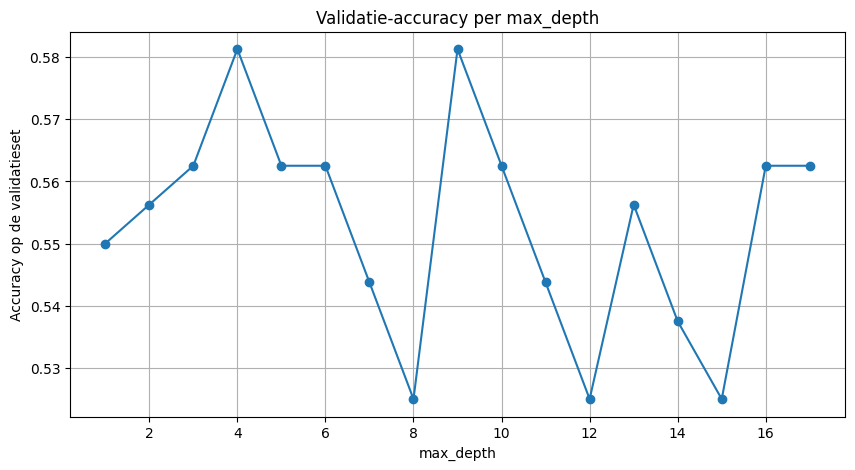

Beste max_depth op basis van validatie-accuracy: 4
Test accuracy van beste boom: 0.597667638483965
Test weighted precision van beste boom: 0.5634261725968472


In [11]:
depths = list(range(1, 18))
validation_accuracy_by_depth = []
validation_precision_by_depth = []
trained_depth_models = {}

for depth in depths:
    model = DecisionTreeClassifier(max_depth=depth, random_state=42)
    model.fit(X_subtrain, y_subtrain)
    val_preds = model.predict(X_val)

    validation_accuracy_by_depth.append(accuracy_score(y_val, val_preds))
    validation_precision_by_depth.append(precision_score(y_val, val_preds, average="weighted", zero_division=0))
    trained_depth_models[depth] = model

results_depth = pd.DataFrame({
    "max_depth": depths,
    "validation_accuracy": validation_accuracy_by_depth,
    "validation_weighted_precision": validation_precision_by_depth,
})

display(results_depth)

best_depth = int(results_depth.loc[results_depth["validation_accuracy"].idxmax(), "max_depth"])

# Retrain met de beste diepte op de volledige trainingsset en evalueer op de testset
best_tree = DecisionTreeClassifier(max_depth=best_depth, random_state=42)
best_tree.fit(X_train, y_train)
best_pred = best_tree.predict(X_test)
best_accuracy = accuracy_score(y_test, best_pred)
best_precision = precision_score(y_test, best_pred, average="weighted", zero_division=0)

plt.figure(figsize=(10, 5))
plt.plot(depths, validation_accuracy_by_depth, marker="o")
plt.xlabel("max_depth")
plt.ylabel("Accuracy op de validatieset")
plt.title("Validatie-accuracy per max_depth")
plt.grid(True)
plt.show()

print(f"Beste max_depth op basis van validatie-accuracy: {best_depth}")
print(f"Test accuracy van beste boom: {best_accuracy}")
print(f"Test weighted precision van beste boom: {best_precision}")

De optimale diepte is de diepte met de beste **generalisatie op de validatieset**, niet gewoon de grootste boom. Daarna gebruik je de **testset** enkel nog voor de finale, eerlijke evaluatie.

##### Question 10: How would you detect overfitting in classification? Do this check for all models you tested in question 8 and plot the results. Would you choose a different max_depth now?

**Antwoord:**  
Bij classificatie detecteer je **overfitting** door de prestaties op de **trainingsdata** en op **niet-gezien data** met elkaar te vergelijken. Als de training accuracy blijft stijgen terwijl de validatie- of test accuracy stagneert of daalt, dan leert het model waarschijnlijk ook ruis en toevallige patronen uit de trainingsdata.

Omdat de testset idealiter onaangeroerd blijft tot de finale evaluatie, vergelijken we hier voor elke boomdiepte de **subtraining accuracy** met de **validatie accuracy**. Een goede keuze voor `max_depth` ligt meestal in de buurt van de hoogste validatiescore, maar met een beperkte kloof tussen train en validatie.

,max_depth,train_accuracy,validation_accuracy,gap
0,1,0.560250,0.55000,0.010250
1,2,0.564945,0.55625,0.008695
2,3,0.594679,0.56250,0.032179
3,4,0.652582,0.58125,0.071332
4,5,0.699531,0.56250,0.137031
5,6,0.758998,0.56250,0.196498
6,7,0.818466,0.54375,0.274716
7,8,0.871674,0.52500,0.346674
8,9,0.917058,0.58125,0.335808
9,10,0.949922,0.56250,0.387422


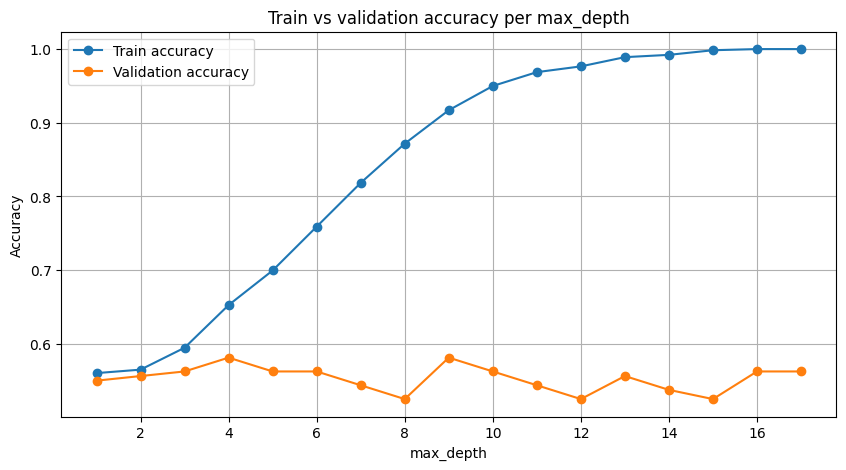

Diepte met hoogste validatie accuracy: 4
Beste compromis tussen hoge validatie accuracy en kleine kloof: 4


In [12]:
train_accuracies = []
validation_accuracies = []

for depth in depths:
    model = DecisionTreeClassifier(max_depth=depth, random_state=42)
    model.fit(X_subtrain, y_subtrain)

    train_accuracies.append(accuracy_score(y_subtrain, model.predict(X_subtrain)))
    validation_accuracies.append(accuracy_score(y_val, model.predict(X_val)))

overfit_df = pd.DataFrame({
    "max_depth": depths,
    "train_accuracy": train_accuracies,
    "validation_accuracy": validation_accuracies,
    "gap": np.array(train_accuracies) - np.array(validation_accuracies),
})

display(overfit_df)

plt.figure(figsize=(10, 5))
plt.plot(depths, train_accuracies, marker="o", label="Train accuracy")
plt.plot(depths, validation_accuracies, marker="o", label="Validation accuracy")
plt.xlabel("max_depth")
plt.ylabel("Accuracy")
plt.title("Train vs validation accuracy per max_depth")
plt.grid(True)
plt.legend()
plt.show()

best_generalizing_depth = int(overfit_df.loc[overfit_df["validation_accuracy"].idxmax(), "max_depth"])

candidate_depths = overfit_df.sort_values(["validation_accuracy", "gap"], ascending=[False, True])
balanced_depth = int(candidate_depths.iloc[0]["max_depth"])

print(f"Diepte met hoogste validatie accuracy: {best_generalizing_depth}")
print(f"Beste compromis tussen hoge validatie accuracy en kleine kloof: {balanced_depth}")

**Interpretatie:**  
Als de diepte uit vraag 9 ook een **aanvaardbare kloof** tussen train en validatie heeft, dan blijft dat mijn voorkeurskeuze. Als de kloof heel groot wordt, kies ik liever een iets **eenvoudigere boom**. In deze oefening kies je dus best de kleinste boom die nog bijna de beste validatieprestatie haalt, en pas daarna bevestig je die keuze op de testset.

##### Question 11: A variant of Decision trees is called 'Random Forest'. In random forest, we create a number of decision trees who each make a prediction and take the average outcome. For classification, this is the outcome that occurs the most over all decision trees. Based on the [documentation](https://scikit-learn.org/dev/modules/generated/sklearn.ensemble.RandomForestClassifier.html#sklearn.ensemble.RandomForestClassifier) (or you can experiment yourself, it is very similar to decision trees so I'm sure you can figure it out!) create a model for a random forest and report on the accuracy/precision.

**Antwoord:**  
Een random forest combineert meerdere decision trees. Daardoor is het model meestal **stabieler** en generaliseert het vaak beter dan één enkele boom. We trainen hieronder een random forest en vergelijken de accuracy en weighted precision met zowel het basismodel als de geoptimaliseerde decision tree.

In [13]:
random_forest = RandomForestClassifier(
    n_estimators=200,
    max_depth=best_depth,
    random_state=42,
)
random_forest.fit(X_train, y_train)

rf_pred = random_forest.predict(X_test)
rf_accuracy = accuracy_score(y_test, rf_pred)
rf_precision = precision_score(y_test, rf_pred, average="weighted", zero_division=0)

comparison = pd.DataFrame({
    "model": [
        "Baseline decision tree",
        f"Decision tree (max_depth={best_depth})",
        "Random forest",
    ],
    "accuracy": [baseline_accuracy, best_accuracy, rf_accuracy],
    "weighted_precision": [baseline_precision, best_precision, rf_precision],
})

comparison

,model,accuracy,weighted_precision
0,Baseline decision tree,0.545190,0.543538
1,Decision tree (max_depth=4),0.597668,0.563426
2,Random forest,0.629738,0.598271


Vaak presteert een random forest beter dan één losse decision tree, omdat het middelen over meerdere bomen de variantie verlaagt en toevallige fouten van één enkele boom afzwakt.

*note: random forest is exam stuff*

##### Question 12: Would a randomforest be more or less prone to overfitting than a decision tree? Study up on the exact workings of a random forest and elaborate.

**Antwoord:**  
Een random forest is in het algemeen **minder gevoelig voor overfitting** dan één enkele decision tree. Dat komt doordat een random forest meerdere bomen traint, voor elke boom een andere bootstrap-steekproef van de data gebruikt en meestal ook maar een deel van de features per split bekijkt.

Daardoor worden de individuele bomen minder sterk aan elkaar gekoppeld. De uiteindelijke voorspelling is een **aggregatie** van al die bomen, waardoor toevallige extreme beslissingen van één boom minder doorwegen. Een enkele decision tree kan heel gemakkelijk ruis in de trainingsdata memoriseren; een random forest maakt dat effect kleiner.

Een random forest kan nog altijd overfitten als je de parameters extreem kiest, maar in de praktijk is het meestal **robuuster** en generaliseert het beter dan één losse decision tree.